In [2]:
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

import matplotlib.pyplot as plt
import pandas as pd

In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

df = pd.read_csv("ai_jobs_salaries_clean.csv")

df["high_salary"] = (df["salary_in_usd"] > df["salary_in_usd"].median()).astype(int)

num_cols = ["work_year", "remote_ratio"]
cat_cols = ["experience_level", "employment_type", "role_family",
            "employee_residence", "company_location", "company_size"]

X = df[num_cols + cat_cols]
y = df["high_salary"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("Data ready:", X_train_prepared.shape, X_test_prepared.shape)

Data ready: (57530, 218) (14383, 218)


In [6]:

logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X_train_prepared, y_train)

logistic_predictions = logistic_model.predict(X_test_prepared)

print("First 10 predictions:", logistic_predictions[:10])
print("First 10 actual values:", y_test.iloc[:10].tolist())

First 10 predictions: [0 0 1 0 1 0 1 1 0 0]
First 10 actual values: [0, 1, 0, 0, 1, 1, 1, 0, 0, 0]


In [8]:
knn_model = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)

knn_model.fit(X_train_prepared, y_train)

knn_predictions = knn_model.predict(X_test_prepared)

print("First 10 KNN predictions:", knn_predictions[:10])
print("First 10 actual values:", y_test.iloc[:10].tolist())

print("Accuracy:", accuracy_score(y_test, knn_predictions))
print(classification_report(y_test, knn_predictions))

First 10 KNN predictions: [0 1 1 0 0 0 1 1 0 0]
First 10 actual values: [0, 1, 0, 0, 1, 1, 1, 0, 0, 0]
Accuracy: 0.5875686574428144
              precision    recall  f1-score   support

           0       0.57      0.74      0.64      7193
           1       0.63      0.44      0.51      7190

    accuracy                           0.59     14383
   macro avg       0.60      0.59      0.58     14383
weighted avg       0.60      0.59      0.58     14383



In [9]:
tree_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

tree_model.fit(X_train_prepared, y_train)

tree_predictions = tree_model.predict(X_test_prepared)

print("First 10 tree predictions:", tree_predictions[:10])

First 10 tree predictions: [0 0 1 0 1 0 1 1 0 0]


In [10]:

def evaluate_model(name, y_true, y_pred):

    print("\nModel:", name)

    print("Accuracy:",
          accuracy_score(y_true, y_pred))

    print("F1-score:",
          f1_score(y_true, y_pred, zero_division=0))

    print("\nClassification report:")
    print(classification_report(
        y_true,
        y_pred,
        target_names=["Did not survive", "Survived"],
        zero_division=0
    ))

    cm = confusion_matrix(y_true, y_pred)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Did not survive", "Survived"]
    )

    display.plot()
    plt.title(name + " Confusion Matrix")
    plt.show()


Model: Logistic Regression
Accuracy: 0.6837933671695752
F1-score: 0.6790402258292166

Classification report:
                 precision    recall  f1-score   support

Did not survive       0.68      0.70      0.69      7193
       Survived       0.69      0.67      0.68      7190

       accuracy                           0.68     14383
      macro avg       0.68      0.68      0.68     14383
   weighted avg       0.68      0.68      0.68     14383



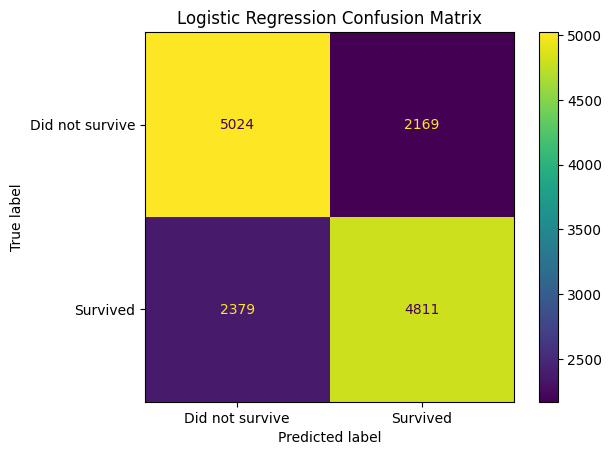


Model: KNN
Accuracy: 0.5875686574428144
F1-score: 0.5145662847790508

Classification report:
                 precision    recall  f1-score   support

Did not survive       0.57      0.74      0.64      7193
       Survived       0.63      0.44      0.51      7190

       accuracy                           0.59     14383
      macro avg       0.60      0.59      0.58     14383
   weighted avg       0.60      0.59      0.58     14383



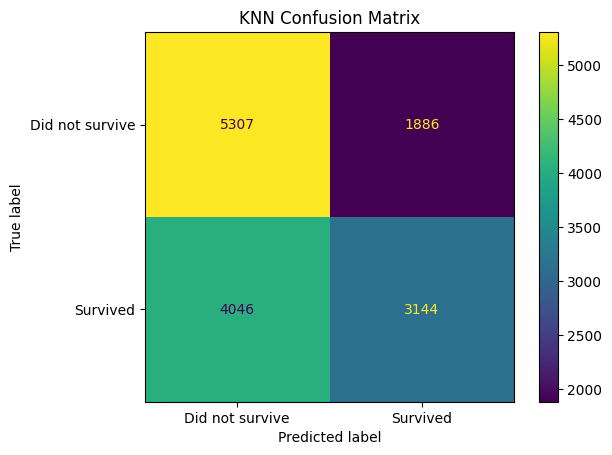


Model: Decision Tree
Accuracy: 0.680456093999861
F1-score: 0.6734867860187553

Classification report:
                 precision    recall  f1-score   support

Did not survive       0.67      0.70      0.69      7193
       Survived       0.69      0.66      0.67      7190

       accuracy                           0.68     14383
      macro avg       0.68      0.68      0.68     14383
   weighted avg       0.68      0.68      0.68     14383



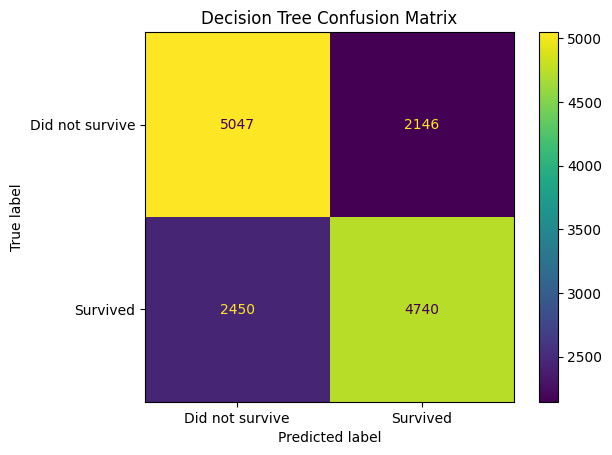

In [11]:
evaluate_model("Logistic Regression",
               y_test, logistic_predictions)

evaluate_model("KNN",
               y_test, knn_predictions)

evaluate_model("Decision Tree",
               y_test, tree_predictions)

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, r2_score

# Features and target
salary_num = ["work_year", "remote_ratio"]
salary_cat = ["experience_level", "employment_type", "role_family",
              "employee_residence", "company_location", "company_size"]

X_salary = df[salary_num + salary_cat]
y_salary = df["salary_in_usd"]

X_salary_train, X_salary_test, y_salary_train, y_salary_test = train_test_split(
    X_salary, y_salary, test_size=0.2, random_state=42
)

# Preprocessing + model in one pipeline
salary_preprocessor = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), salary_num),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=100), salary_cat),
])

salary_model = make_pipeline(salary_preprocessor, LinearRegression())

salary_model.fit(X_salary_train, y_salary_train)

salary_predictions = salary_model.predict(X_salary_test)

print("Actual salaries:", y_salary_test.head().tolist())
print("Predicted salaries:", [round(p) for p in salary_predictions[:5]])

print("Mean Absolute Error:", mean_absolute_error(y_salary_test, salary_predictions))
print("R² score:", r2_score(y_salary_test, salary_predictions))

Actual salaries: [90900, 256470, 192986, 185500, 122500]
Predicted salaries: [92067, 175348, 216888, 145066, 209090]
Mean Absolute Error: 49936.91398026966
R² score: 0.21820957970736699


In [14]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Decision Tree"
    ],
    "Accuracy": [
        accuracy_score(y_test, logistic_predictions),
        accuracy_score(y_test, knn_predictions),
        accuracy_score(y_test, tree_predictions)
    ],
    "F1-score": [
        f1_score(y_test, logistic_predictions),
        f1_score(y_test, knn_predictions),
        f1_score(y_test, tree_predictions)
    ]
})

print(results.round(3))

                 Model  Accuracy  F1-score
0  Logistic Regression     0.684     0.679
1                  KNN     0.588     0.515
2        Decision Tree     0.680     0.673


# New Section